# nb02 — Paper-guided QC and preprocessing
**Question:** Which paired cells and genes pass the RNA QC thresholds reported by Kupp et al.,
and how can we prepare RNA and ATAC while preserving counts and exact pairing?
Reference: [Kupp et al., Communications Biology (2025)](https://doi.org/10.1038/s42003-025-08533-7),
Methods, p.14, “Standard single-cell analysis workflow”.
This is the paper's standard-analysis QC branch, not a claim that its scMKL models used the same filtering.
No DE, GSEA, motif analysis, dimensionality reduction, clustering or models are run here.

In [1]:
try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True
    drive.mount('/content/drive')
from pathlib import Path
import os
BASE = Path("/content/drive/MyDrive/breast-cancer-multiome-estrogen") if IN_COLAB else Path(os.environ.get("MULTIOME_PROJECT_ROOT", Path.cwd())).resolve()
if BASE.name == "notebooks":
    BASE = BASE.parent
DATA_DIR = BASE / "data/raw/GSE154873"
RESULTS_DIR = BASE / "results"
assert (DATA_DIR / "download_manifest.json").is_file(), "Run nb00 first."
print("Project:", BASE)
print("Inputs:", DATA_DIR)
print("Processed:", BASE / "data/processed")

Project: /home/shoko/breast-cancer-multiome-estrogen
Inputs: /home/shoko/breast-cancer-multiome-estrogen/data/raw/GSE154873
Processed: /home/shoko/breast-cancer-multiome-estrogen/data/processed


In [2]:
import importlib.util, subprocess, sys
packages = {"anndata":"anndata", "numpy":"numpy", "pandas":"pandas", "scipy":"scipy", "matplotlib":"matplotlib"}
missing = [package for module,package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable,"-m","pip","install",*missing])
print("Python:",sys.version)

Python: 3.11.17 (main, Oct  7 2026, 00:02:24) [GCC 15.3.0]


## Parameters and interpretation
Keep genes detected in **at least 3 cells**; keep cells with **at least 100 detected genes**
and **mitochondrial counts ≤30%**. Exactly 30% passes. Human mitochondrial genes are recognized by MT-.
We implement one gene-first pass, then compute cell QC on the retained genes, separately per cell line.
Filter order, MT- recognition and scaling ddof=1 are explicit implementation choices, not fully specified paper parameters.
The paper supplies no library-size normalization target: use log1p(counts) and record sample-standard-deviation
scaling with no clipping. All choices are visible below.
No ATAC-specific cutoff is invented. Apply the identical RNA cell mask; retain all peaks.
Peak counts are not fragment counts. TSS enrichment, FRiP and nucleosome metrics need unavailable fragment-level inputs.

In [3]:
import json
CONFIG = json.loads('{"reference_doi": "10.1038/s42003-025-08533-7", "reference_section": "Methods / Unsupervised algorithms / Standard single-cell analysis workflow, p.14", "min_cells_per_gene": 3, "min_genes_per_cell": 100, "max_pct_mitochondrial": 30.0, "mitochondrial_prefix": "MT-", "filter_order": "gene prevalence on supplied cells, then cell metrics on retained genes; one pass", "rna_transform": "log1p counts; no unspecified library-size normalization", "scaling_ddof": 1, "scaling_clip": null, "atac_cell_filter": "same RNA-selected paired cells", "atac_peak_filter": null, "atac_extra_cell_thresholds": null, "atac_layers": ["binary"], "prediction_fit_scope": "Refit feature selection/scaling/IDF on training data later", "expected": {"MCF7": {"cells": 6438, "rna_features": 36601, "atac_features": 206167}, "T47D": {"cells": 6615, "rna_features": 36601, "atac_features": 206167}}}')
print(json.dumps(CONFIG,indent=2))

{
  "reference_doi": "10.1038/s42003-025-08533-7",
  "reference_section": "Methods / Unsupervised algorithms / Standard single-cell analysis workflow, p.14",
  "min_cells_per_gene": 3,
  "min_genes_per_cell": 100,
  "max_pct_mitochondrial": 30.0,
  "mitochondrial_prefix": "MT-",
  "filter_order": "gene prevalence on supplied cells, then cell metrics on retained genes; one pass",
  "rna_transform": "log1p counts; no unspecified library-size normalization",
  "scaling_ddof": 1,
  "scaling_clip": null,
  "atac_cell_filter": "same RNA-selected paired cells",
  "atac_peak_filter": null,
  "atac_extra_cell_thresholds": null,
  "atac_layers": [
    "binary"
  ],
  "prediction_fit_scope": "Refit feature selection/scaling/IDF on training data later",
  "expected": {
    "MCF7": {
      "cells": 6438,
      "rna_features": 36601,
      "atac_features": 206167
    },
    "T47D": {
      "cells": 6615,
      "rna_features": 36601,
      "atac_features": 206167
    }
  }
}


## Sparse implementation
The next cell is generated from src/qc_preprocessing.py, so this notebook runs without source uploads.
Inputs must match nb00's SHA-256 manifest. Only one dense text row is parsed at a time.
RNA .X contains log1p counts; layers['counts'] contains integers.
Centered scaling is stored as a sparse scaled_no_center layer plus var['scale_center_offset']:
z = scaled_no_center - scale_center_offset. Use centered_scaled_block only on small requested blocks.
ATAC .X contains integer peak counts and layers['binary'] contains accessibility indicators.
The four .h5ad files are written under data/processed/ and overwritten deterministically when rerun.

In [4]:
"""Paper-guided RNA QC and paired sparse preprocessing, without downstream analysis."""
import gc
import gzip
import hashlib
import json
import warnings
from array import array
from datetime import datetime, timezone
from pathlib import Path
import anndata as ad
import numpy as np
import pandas as pd
from scipy import sparse

def file_hash(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

def read_sparse_counts(path):
    """Parse one dense-text row at a time, then transpose verified features x cells."""
    values, indices, indptr = array("i"), array("i"), array("q", [0])
    features = []
    with gzip.open(path, "rt") as f:
        cells = f.readline().rstrip("\r\n").split("\t")
        if not cells or any(not cell for cell in cells) or len(set(cells)) != len(cells):
            raise ValueError(f"Missing or duplicate cell IDs in {path}")
        for line_number, line in enumerate(f, start=2):
            feature, sep, text = line.rstrip("\r\n").partition("\t")
            if not sep or text.count("\t") + 1 != len(cells):
                raise ValueError(f"Unexpected row width at {path}:{line_number}")
            with warnings.catch_warnings():
                warnings.simplefilter("error", DeprecationWarning)
                row = np.fromstring(text, sep="\t", dtype=np.float64)
            if (row.size != len(cells) or not np.isfinite(row).all() or
                    (row < 0).any() or (row != np.floor(row)).any() or
                    (row > np.iinfo(np.int32).max).any()):
                raise ValueError(f"Invalid integer counts at {path}:{line_number}")
            nz = np.flatnonzero(row)
            values.frombytes(row[nz].astype(np.int32).tobytes())
            indices.frombytes(nz.astype(np.int32).tobytes())
            indptr.append(len(values))
            features.append(feature)
            if len(features) % 25000 == 0:
                print(f"  {Path(path).name}: {len(features):,} features", flush=True)
    if not features or len(features) != len(set(features)) or any(not x for x in features):
        raise ValueError(f"Missing or duplicated feature IDs: {path}")
    matrix = sparse.csr_matrix((np.frombuffer(values, dtype=np.int32),
                               np.frombuffer(indices, dtype=np.int32),
                               np.frombuffer(indptr, dtype=np.int64)),
                              shape=(len(features), len(cells))).T.tocsr()
    return matrix, pd.Index(cells, name="cell_id"), pd.Index(features, name="feature_id")

def read_metadata(path, expected_cells, cell_line):
    frame = pd.read_csv(path, sep="\t", header=None, dtype=str, keep_default_na=False)
    if frame.shape[1] != 2:
        raise ValueError("Expected the inspected two-column headerless metadata.")
    frame.columns = ["cell_id", "sample_label"]
    if frame.cell_id.duplicated().any() or not frame.cell_id.tolist() == list(expected_cells):
        raise ValueError("Metadata cells/order do not exactly match the count matrix.")
    frame = frame.set_index("cell_id")
    mapping = {"YW_si_Control_plus_E2": "E2", "YW_si_Control_plus_Veh": "Vehicle"}
    if not set(frame.sample_label).issubset(mapping):
        raise ValueError("Unrecognized treatment labels.")
    frame["treatment"] = frame.sample_label.map(mapping)
    frame["cell_line"] = cell_line
    frame["global_cell_id"] = cell_line + ":" + frame.index
    return frame

def rna_qc(counts, genes, config):
    """One-pass gene-first filtering; boundaries follow the paper's inequalities."""
    gene_detected = np.asarray((counts > 0).sum(axis=0)).ravel()
    gene_keep = gene_detected >= config["min_cells_per_gene"]
    selected = counts[:, gene_keep].tocsr()
    mt = np.array([str(g).startswith(config["mitochondrial_prefix"]) for g in genes])
    if not mt.any():
        raise ValueError("No mitochondrial genes detected; verify gene naming before QC.")
    total_before = np.asarray(counts.sum(axis=1)).ravel()
    total = np.asarray(selected.sum(axis=1)).ravel()
    detected = np.diff(selected.indptr)
    mitochondrial = np.asarray(selected[:, mt[gene_keep]].sum(axis=1)).ravel()
    pct_mt = np.divide(100.0 * mitochondrial, total, out=np.full(total.shape, np.nan),
                       where=total > 0)
    keep_genes = detected >= config["min_genes_per_cell"]
    keep_mt = np.isfinite(pct_mt) & (pct_mt <= config["max_pct_mitochondrial"])
    keep = keep_genes & keep_mt
    qc = pd.DataFrame({
        "rna_total_counts_before_gene_filter": total_before,
        "rna_n_genes_before_gene_filter": np.diff(counts.indptr),
        "rna_total_counts": total, "rna_n_genes": detected, "rna_pct_counts_mt": pct_mt,
        "pass_min_genes": keep_genes, "pass_max_pct_mt": keep_mt, "pass_rna_qc": keep})
    var = pd.DataFrame({"n_cells_detected_before_qc": gene_detected,
                        "pass_min_cells": gene_keep, "mt": mt}, index=genes)
    return keep, gene_keep, qc, var

def sparse_log_and_scale(counts, ddof=1):
    """Centered z-scores represented as sparse scaled values minus offsets."""
    log = counts.astype(np.float32)
    np.log1p(log.data, out=log.data)
    mean = np.asarray(log.mean(axis=0, dtype=np.float64)).ravel()
    second = np.asarray(log.astype(np.float64).power(2).mean(axis=0)).ravel()
    variance = np.maximum(second - mean**2, 0)
    if log.shape[0] <= ddof:
        raise ValueError("Too few cells to estimate scaling variance.")
    std = np.sqrt(variance * log.shape[0] / (log.shape[0] - ddof))
    std[std == 0] = 1
    scaled = log.multiply(1 / std).astype(np.float32).tocsr()
    return log, scaled, mean, std

def centered_scaled_block(adata, rows, columns):
    """Materialize only an explicitly requested small block of centered z-scores."""
    block = adata.layers["scaled_no_center"][rows, :][:, columns]
    if block.shape[0] * block.shape[1] > 5_000_000:
        raise ValueError("Request a smaller block; full centered matrices are not materialized.")
    offset = adata.var["scale_center_offset"].to_numpy()[columns]
    return block.toarray() - offset

def save_h5ad(adata, path):
    path = Path(path)
    temp = path.with_name(path.stem + ".partial.h5ad")
    adata.write_h5ad(temp, compression="gzip")
    check = ad.read_h5ad(temp, backed="r")
    try:
        if check.shape != adata.shape or not check.obs_names.equals(adata.obs_names):
            raise ValueError(f"Written AnnData validation failed: {path}")
    finally:
        check.file.close()
    temp.replace(path)

def qc_figure(qc, cell_line, config, output):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), constrained_layout=True)
    for ax, col, title in zip(axes, ["rna_n_genes", "rna_pct_counts_mt", "atac_n_peaks"],
                             ["Detected RNA genes", "Mitochondrial RNA (%)", "Detected ATAC peaks"]):
        edges = np.histogram_bin_edges(qc[col].dropna(), bins=50)
        ax.hist(qc[col], bins=edges, color="#aebbc9", label="All supplied cells")
        ax.hist(qc.loc[qc.pass_rna_qc, col], bins=edges, histtype="step", linewidth=1.8,
                color="#176b63", label="RNA QC retained")
        ax.set_title(title)
        ax.set_ylabel("Cells")
    axes[0].axvline(config["min_genes_per_cell"], color="#bd4b35", linestyle="--")
    axes[1].axvline(config["max_pct_mitochondrial"], color="#bd4b35", linestyle="--")
    axes[2].legend(fontsize=8)
    fig.suptitle(f"{cell_line}: paper-guided QC; ATAC follows the same cell mask")
    fig.savefig(output, dpi=160)
    plt.close(fig)

def preprocess_line(root, cell_line, config):
    root = Path(root)
    raw = root / "data/raw/GSE154873"
    output = root / "data/processed"
    tables, figures = root / "results/tables", root / "results/figures"
    for folder in (output, tables, figures):
        folder.mkdir(parents=True, exist_ok=True)
    prefix = f"GSE154873_{cell_line}_multiome_"
    sources = {name: raw / (prefix + suffix + ".tsv.gz") for name, suffix in
               (("rna", "RNA_counts"), ("atac", "ATAC_counts"), ("metadata", "metadata"))}
    manifest = json.loads((raw / "download_manifest.json").read_text())
    source_hashes = {}
    for name, path in sources.items():
        source_hashes[name] = file_hash(path)
        if source_hashes[name] != manifest["files"][f"{cell_line.lower()}_{name}"]["sha256"]:
            raise ValueError(f"Input differs from inspected download: {path}")
    print(f"\n{cell_line}: reading RNA", flush=True)
    counts, cells, genes = read_sparse_counts(sources["rna"])
    expected = config["expected"][cell_line]
    if counts.shape != (expected["cells"], expected["rna_features"]):
        raise ValueError("RNA dimensions differ from inspected paper dataset.")
    obs = read_metadata(sources["metadata"], cells, cell_line)
    cell_keep, gene_keep, qc, var = rna_qc(counts, genes, config)
    qc.index = cells
    qc = obs.join(qc)
    if not cell_keep.any():
        raise ValueError("QC retained no cells.")
    kept_counts = counts[cell_keep, :][:, gene_keep].tocsr()
    del counts
    log, scaled, mean, std = sparse_log_and_scale(kept_counts, config["scaling_ddof"])
    rna = ad.AnnData(X=log, obs=qc.loc[cell_keep].copy(), var=var.loc[gene_keep].copy())
    rna.layers["counts"] = kept_counts
    rna.layers["scaled_no_center"] = scaled
    rna.var["log1p_mean"] = mean
    rna.var["log1p_std"] = std
    rna.var["scale_center_offset"] = mean / std
    rna.uns["preprocessing"] = {
        "reference_doi": config["reference_doi"], "config_json": json.dumps(config),
        "X": "log1p(raw counts), no library-size normalization",
        "counts": "Unmodified integer counts for retained cells and genes",
        "centered_scale": "scaled_no_center - var.scale_center_offset",
        "scale_scope": "descriptive per cell line; refit inside future training folds",
        "filter_order": config["filter_order"], "source_sha256_json": json.dumps(source_hashes)}
    rna_path = output / f"{cell_line}_RNA_paper_qc.h5ad"
    save_h5ad(rna, rna_path)
    del rna, kept_counts, log, scaled
    gc.collect()
    print(f"{cell_line}: reading paired ATAC", flush=True)
    atac_counts, atac_cells, peaks = read_sparse_counts(sources["atac"])
    if atac_counts.shape != (expected["cells"], expected["atac_features"]) or not atac_cells.equals(cells):
        raise ValueError("ATAC dimensions or exact cell order differ from RNA.")
    qc["atac_total_peak_counts"] = np.asarray(atac_counts.sum(axis=1)).ravel()
    qc["atac_n_peaks"] = np.diff(atac_counts.indptr)
    qc["atac_zero_counts"] = qc.atac_total_peak_counts == 0
    selected = atac_counts[cell_keep].tocsr()
    del atac_counts
    atac_var = pd.DataFrame(index=peaks)
    coordinates = [peak.rsplit("-", 2) for peak in peaks]
    if any(len(x) != 3 or not x[1].isdigit() or not x[2].isdigit() or int(x[1]) >= int(x[2])
           for x in coordinates):
        raise ValueError("Unrecognized peak coordinates.")
    atac_var["contig"] = [x[0] for x in coordinates]
    atac_var["start_as_supplied"] = [int(x[1]) for x in coordinates]
    atac_var["end_as_supplied"] = [int(x[2]) for x in coordinates]
    atac_var["n_cells_detected_after_rna_qc"] = np.asarray((selected > 0).sum(axis=0)).ravel()
    atac = ad.AnnData(X=selected, obs=qc.loc[cell_keep].copy(), var=atac_var)
    binary = selected.astype(np.uint8)
    binary.data[:] = 1
    atac.layers["binary"] = binary
    atac.uns["preprocessing"] = {
        "reference_doi": config["reference_doi"], "config_json": json.dumps(config),
        "X": "Unmodified integer ATAC peak counts for RNA-QC retained cells; all supplied peaks",
        "binary": "1 for count > 0, otherwise 0",
        "qc_limit": "RNA cell mask only; no fragment-level metrics or ATAC-specific thresholds available",
        "coordinates": "As supplied; genome build and coordinate origin unresolved",
        "source_sha256_json": json.dumps(source_hashes)}
    atac_path = output / f"{cell_line}_ATAC_paired_paper_qc.h5ad"
    save_h5ad(atac, atac_path)
    qc.to_csv(tables / f"{cell_line}_cell_qc.tsv", sep="\t", lineterminator="\n")
    var.to_csv(tables / f"{cell_line}_gene_qc.tsv", sep="\t", lineterminator="\n")
    qc_figure(qc, cell_line, config, figures / f"{cell_line}_paper_qc.png")
    summary = {
        "cells_before": len(cells), "cells_after": int(cell_keep.sum()),
        "genes_before": len(genes), "genes_after": int(gene_keep.sum()),
        "atac_peaks_before": len(peaks), "atac_peaks_after": len(peaks),
        "fail_min_genes": int((~qc.pass_min_genes).sum()),
        "fail_max_pct_mt": int((~qc.pass_max_pct_mt).sum()),
        "fail_both": int(((~qc.pass_min_genes) & (~qc.pass_max_pct_mt)).sum()),
        "atac_zero_count_cells_retained": int(qc.loc[cell_keep, "atac_zero_counts"].sum()),
        "treatment_before": {k:int(v) for k,v in qc.treatment.value_counts().items()},
        "treatment_after": {k:int(v) for k,v in qc.loc[cell_keep].treatment.value_counts().items()},
        "source_sha256": source_hashes, "exact_paired_order": True,
        "outputs": [str(rna_path.relative_to(root)), str(atac_path.relative_to(root))]}
    saved_rna, saved_atac = ad.read_h5ad(rna_path, backed="r"), ad.read_h5ad(atac_path, backed="r")
    try:
        if not saved_rna.obs_names.equals(saved_atac.obs_names):
            raise ValueError("Written RNA/ATAC cells no longer match.")
    finally:
        saved_rna.file.close()
        saved_atac.file.close()
    print(json.dumps(summary, indent=2), flush=True)
    del atac, selected, binary
    gc.collect()
    return summary

def run_preprocessing(root, config):
    report = {"reference_doi": config["reference_doi"], "config": config,
              "run_at_utc": datetime.now(timezone.utc).isoformat(), "cell_lines": {}}
    for cell_line in ("MCF7", "T47D"):
        report["cell_lines"][cell_line] = preprocess_line(root, cell_line, config)
    destination = Path(root) / "results/tables/paper_qc_summary.json"
    destination.write_text(json.dumps(report, indent=2) + "\n")
    return report

In [5]:
report = run_preprocessing(BASE, CONFIG)


MCF7: reading RNA


  GSE154873_MCF7_multiome_RNA_counts.tsv.gz: 25,000 features


MCF7: reading paired ATAC


  GSE154873_MCF7_multiome_ATAC_counts.tsv.gz: 25,000 features


  GSE154873_MCF7_multiome_ATAC_counts.tsv.gz: 50,000 features


...

  GSE154873_T47D_multiome_ATAC_counts.tsv.gz: 125,000 features


  GSE154873_T47D_multiome_ATAC_counts.tsv.gz: 150,000 features


  GSE154873_T47D_multiome_ATAC_counts.tsv.gz: 175,000 features


  GSE154873_T47D_multiome_ATAC_counts.tsv.gz: 200,000 features


{
  "cells_before": 6615,
  "cells_after": 6562,
  "genes_before": 36601,
  "genes_after": 26320,
  "atac_peaks_before": 206167,
  "atac_peaks_after": 206167,
  "fail_min_genes": 0,
  "fail_max_pct_mt": 53,
  "fail_both": 0,
  "atac_zero_count_cells_retained": 0,
  "treatment_before": {
    "E2": 3587,
    "Vehicle": 3028
  },
  "treatment_after": {
    "E2": 3565,
    "Vehicle": 2997
  },
  "source_sha256": {
    "rna": "576f0d067d91f8e435b4bd3fa47cb1cbc541d724293965ad629dd52047f3004f",
    "atac": "6c72f18ef3fcf49e7a4d5971e6aa4073b4982c8c1ab8a8e9ed810e2ab954bce7",
    "metadata": "e36d108ab2aae925007f0d5dee10cba8a2be0308aac0570a4109f54903bca542"
  },
  "exact_paired_order": true,
  "outputs": [
    "data/processed/T47D_RNA_paper_qc.h5ad",
    "data/processed/T47D_ATAC_paired_paper_qc.h5ad"
  ]
}


In [6]:
summary = pd.DataFrame({line: {k:v for k,v in values.items() if isinstance(v,(int,bool))}
                        for line,values in report["cell_lines"].items()}).T
display(summary)
for line, values in report["cell_lines"].items():
    print(line,"treatments before:",values["treatment_before"],"after:",values["treatment_after"])
    print("Exact RNA–ATAC order preserved:",values["exact_paired_order"])

,cells_before,cells_after,genes_before,genes_after,atac_peaks_before,atac_peaks_after,fail_min_genes,fail_max_pct_mt,fail_both,atac_zero_count_cells_retained,exact_paired_order
MCF7,6438,6019,36601,25105,206167,206167,0,419,0,0,True
T47D,6615,6562,36601,26320,206167,206167,0,53,0,0,True


MCF7 treatments before: {'E2': 3443, 'Vehicle': 2995} after: {'E2': 3289, 'Vehicle': 2730}
Exact RNA–ATAC order preserved: True
T47D treatments before: {'E2': 3587, 'Vehicle': 3028} after: {'E2': 3565, 'Vehicle': 2997}
Exact RNA–ATAC order preserved: True


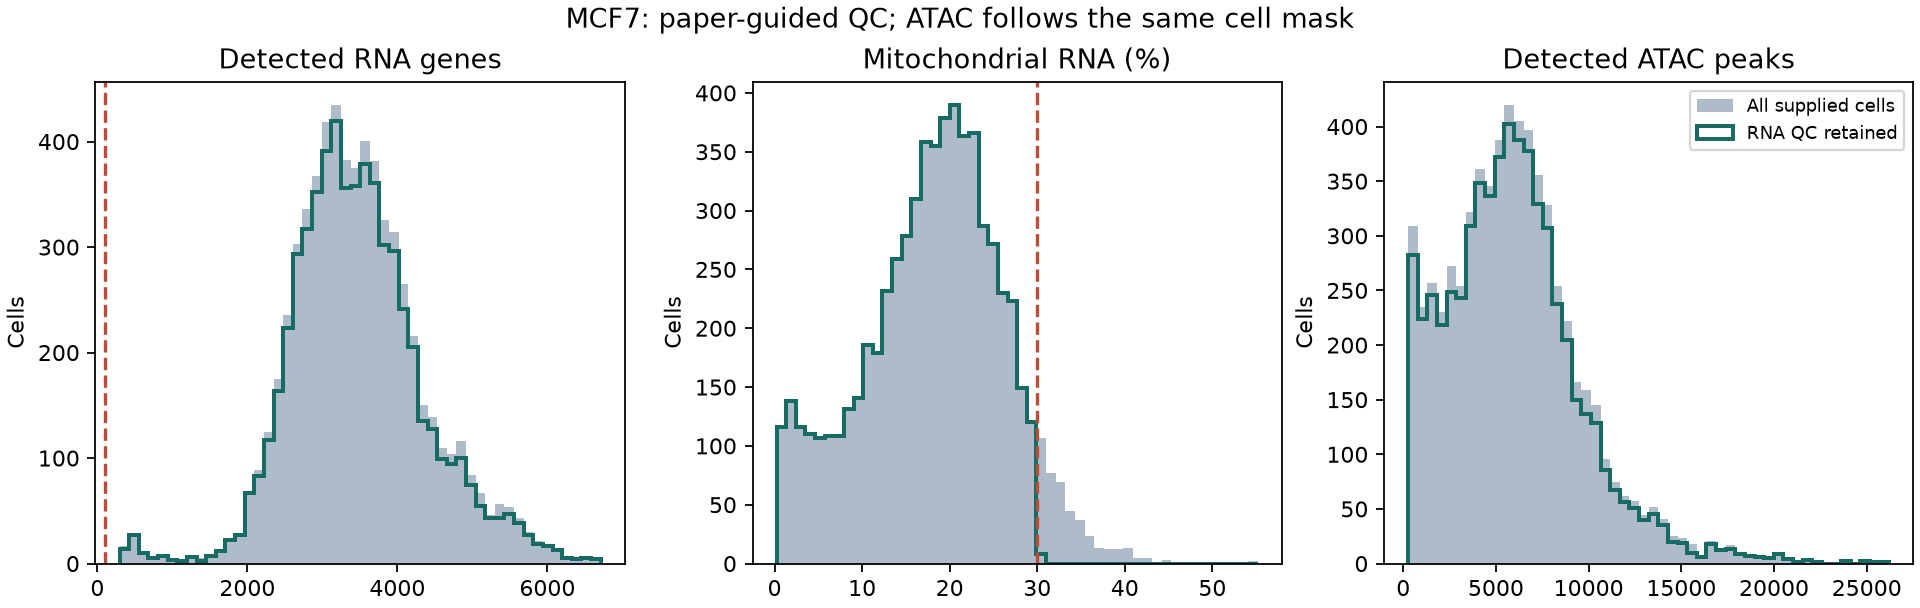

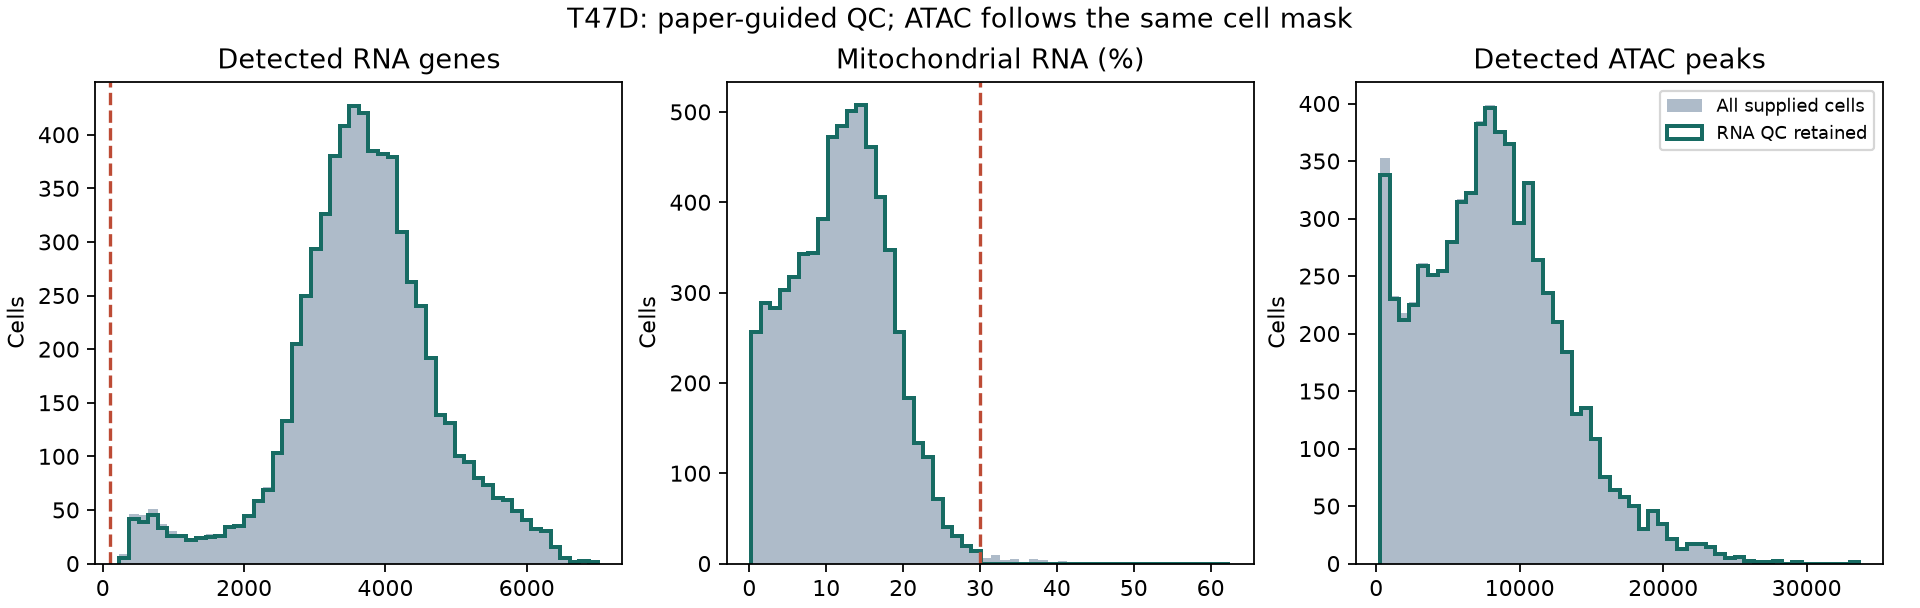

In [7]:
from IPython.display import Image, display
for line in ("MCF7","T47D"):
    display(Image(filename=str(RESULTS_DIR / "figures" / f"{line}_paper_qc.png")))

## Provenance and limits
Table 1 matches the downloaded pre-QC dimensions and treatment counts exactly.
The scMKL paper describes 24-hour estrogen treatment (p.12), whereas the original Ors et al. paper
describes 48 hours for Multiome. Duration is unresolved across publications and is not changed in metadata.
The paper tests multiple scMKL representations. Its explicit ATAC TF-IDF uses count/binary values multiplied
by log(1 + (1+n_cells)/(1+n_detected_cells)), without the usual per-cell term-frequency division.
TF-IDF, feature selection, PCA/LSI and predictive scaling must be fitted inside training splits later;
this QC notebook does not fit them globally for prediction.
The descriptive RNA scaling here is not a reusable fitted transform for held-out classification.
Original archives remain untouched; they retain all original cells/features for a later scMKL-faithful branch.
See QC_PREPROCESSING.md for provenance, assumptions, outputs and validation.
Next: review QC results before nb03 RNA differential expression. Stop here.